In [1]:
# Import libraries. You may or may not use all of these.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
  # %tensorflow_version only exists in Colab.
  %tensorflow_version 2.x
except Exception:
  pass
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

In [2]:
# Import data
!wget https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv
dataset = pd.read_csv('insurance.csv')
dataset.tail()

--2026-11-10 02:25:44--  https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv
Resolving cdn.freecodecamp.org (cdn.freecodecamp.org)... 172.67.70.149, 104.26.3.33, 104.26.2.33
Connecting to cdn.freecodecamp.org (cdn.freecodecamp.org)|172.67.70.149|:443... connected.
HTTP request sent, awaiting response... 

200 OK
Length: 50264 (49K) [text/csv]
Saving to: ‘insurance.csv’

insurance.csv       100%[===================>]  49.09K  --.-KB/s    in 0.001s  

2026-11-10 02:25:44 (32.4 MB/s) - ‘insurance.csv’ saved [50264/50264]



,age,sex,bmi,children,smoker,region,expenses
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95
1337,61,female,29.1,0,yes,northwest,29141.36


In [3]:
# Turn categorical columns into numbers (one-hot encoding).
data = pd.get_dummies(dataset, columns=['sex', 'smoker', 'region'], dtype='float32')

# 80% of the rows for training, 20% for testing.
train_dataset = data.sample(frac=0.8, random_state=0)
test_dataset = data.drop(train_dataset.index)

train_labels = train_dataset.pop('expenses')
test_labels = test_dataset.pop('expenses')

train_dataset = train_dataset.astype('float32')
test_dataset = test_dataset.astype('float32')

# Scale every feature using statistics of the training set.
normalizer = layers.Normalization()
normalizer.adapt(np.array(train_dataset))

tf.random.set_seed(0)
model = keras.Sequential([
    keras.Input(shape=(train_dataset.shape[1],)),
    normalizer,
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05),
              loss='mae',
              metrics=['mae', 'mse'])

history = model.fit(train_dataset, train_labels, epochs=200,
                    validation_split=0.2, verbose=0)
print('Final validation MAE:', round(history.history['val_mae'][-1], 2))

Final validation MAE: 1670.09


9/9 - 0s - 1ms/step - loss: 2279.6155 - mae: 2279.6155 - mse: 34760140.0000


Testing set Mean Abs Error: 2279.62 expenses
You passed the challenge. Great job!
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


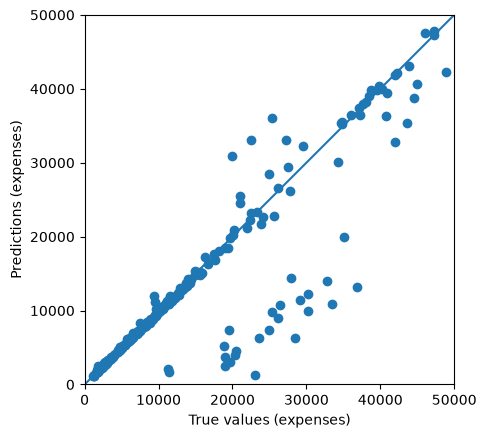

In [4]:
# RUN THIS CELL TO TEST YOUR MODEL. DO NOT MODIFY CONTENTS.
# Test model by checking how well the model generalizes using the test set.
loss, mae, mse = model.evaluate(test_dataset, test_labels, verbose=2)

print("Testing set Mean Abs Error: {:5.2f} expenses".format(mae))

if mae < 3500:
  print("You passed the challenge. Great job!")
else:
  print("The Mean Abs Error must be less than 3500. Keep trying.")

# Plot predictions.
test_predictions = model.predict(test_dataset).flatten()

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True values (expenses)')
plt.ylabel('Predictions (expenses)')
lims = [0, 50000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims,lims)
